In [131]:
import os
from typing import TypedDict
from langgraph.graph import StateGraph,START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [132]:
load_dotenv(override=True)  # Load credentials from the project .env file.

google_api_key = os.getenv("GOOGLE_API_KEY")
if not google_api_key:
    raise ValueError(
        "Set GOOGLE_API_KEY in .env to a valid Google AI Studio API key; "
        "do not use an OAuth access token."
    )

In [133]:
class SubState(TypedDict):
    input_text: str
    translated_text: str


In [134]:
primary = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=google_api_key,
    max_retries=3,
)
backup = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key,
    max_retries=3,
)

model = primary.with_fallbacks([backup])

subgraph_llm = model

In [135]:
def translate_text(state: SubState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["input_text"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'translated_text': translated_text}


In [136]:
subgraph = StateGraph(SubState)
subgraph.add_node("translate_text",translate_text)
subgraph.add_edge(START,"translate_text")
subgraph.add_edge("translate_text",END)

In [137]:
subgraph = subgraph.compile()

In [138]:
class ParentState(TypedDict):
    question: str
    answer_eng: str
    answer_hin: str


In [139]:
parent_llm = model

In [140]:
def generate_answer(state: ParentState):
    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}


In [141]:
def translate_answer(state: ParentState):

    # call the subgraph
    result = subgraph.invoke({'input_text': state['answer_eng']})

    return {'answer_hin': result['translated_text']}


In [142]:
parent_builder = StateGraph(ParentState)
parent_builder.add_node('generate_answer',generate_answer)
parent_builder.add_node('translate_answer',translate_answer)

parent_builder.add_edge(START,'generate_answer')
parent_builder.add_edge('generate_answer','translate_answer')
parent_builder.add_edge('translate_answer',END)

In [143]:
graph = parent_builder.compile()

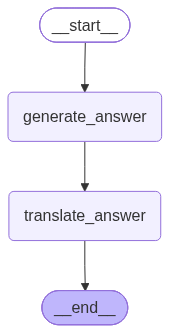

In [144]:
graph

In [145]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': [{'type': 'text',
   'text': '**Quantum physics** (also known as quantum mechanics) is the branch of science that studies matter'},
  {'type': 'text',
   'text': ' and energy at the most fundamental level—specifically, at the scale of atoms and subatomic particles (like electrons and photons).\n\nWhile classical physics (Newton\'s laws) explains how the everyday world works—like how a thrown baseball moves—it fails when applied to extremely small things. At the subatomic level, nature behaves according to a completely different, counterintuitive set of rules.\n\nHere are the key concepts that define quantum physics:\n\n---\n\n### 1. Quantization (Energy in "Packets")\nIn our macroscopic world, things change smoothly (like a car accelerating up a ramp). In the quantum world, things change in fixed, specific steps (like climbing a staircase). Energy is absorbed or emitted in tiny, indivisible packets called **quanta** (singular: *qua